# Tugas 1 — Data Preprocessing
**Mata Kuliah:** Data Mining SI 5-B  
**Nama / NIM:** Achmad Herdifan Aydil Pratama  / 3022410036  
**Partner:** Danang prajadinata Adiwijaya
>

## 0. Persiapan
**Input:** library & file CSV. **Proses:** import library, baca data. **Output:** DataFrame `df`.

In [6]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
FILE_DATA = '/content/drive/MyDrive/Dataset_Pelanggan_TokoOnline.csv'
df = pd.read_csv(FILE_DATA)
R = {}   # menyimpan hasil utk laporan
R['shape_awal'] = list(df.shape)
print(df.shape); df.head(10)

(124, 14)


,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Pendapatan_Bulanan,Frekuensi_Belanja,Total_Belanja,Kategori_Produk,Metode_Pembayaran,Berat_Paket,Satuan_Berat,Tingkat_Kepuasan,Langganan_Premium
0,CUST001,Citra Utami,Perempuan,40.0,Surabaya,12000000.0,9.0,2237000.0,Rumah Tangga,E-Wallet,4.3,kg,Tinggi,Tidak
1,CUST002,Reza Kurniawan,Laki-laki,23.0,Malang,6700000.0,12.0,1748000.0,Kecantikan,Transfer Bank,0.9,kg,Tinggi,Tidak
2,CUST003,Ilham Utami,Laki-laki,17.0,Sidoarjo,10400000.0,5.0,1249000.0,Rumah Tangga,transfer bank,1900.0,g,Sedang,Tidak
3,CUST004,NaN,Perempuan,41.0,Malang,NaN,6.0,NaN,Rumah Tangga,COD,4.1,kg,Sedang,Tidak
4,CUST005,Rizky Hakim,laki-laki,27.0,Malang,8600000.0,6.0,531000.0,Kecantikan,E-Wallet,400.0,g,Tinggi,Tidak
5,CUST006,Hendra Susanto,laki-laki,NaN,Surabaya,9000000.0,NaN,758000.0,Rumah Tangga,NaN,0.3,kg,Sedang,Ya
6,CUST007,Fajar Santoso,Laki-laki,45.0,Surabaya,8700000.0,8.0,2092000.0,Fashion,E-Wallet,1200.0,g,NaN,Tidak
7,CUST008,Dimas Saputra,Laki-laki,39.0,sidoarjo,9200000.0,6.0,829000.0,Fashion,Kartu Kredit,4.7,kg,Tinggi,Ya
8,CUST009,Sari Nugroho,Perempuan,35.0,Surabaya,6000000.0,10.0,1748000.0,kecantikan,Transfer Bank,2.6,kg,Sedang,Tidak
9,CUST010,Reza Kurniawan,Laki-laki,39.0,Surabaya,120000000.0,NaN,1864000.0,Kecantikan,Kartu Kredit,1.1,kg,Tinggi,ya


## 1. Retrieving Data — Memahami Data Mentah
**Input:** `df` mentah. **Proses:** cek tipe data, statistik deskriptif, jumlah missing, dan nilai unik kolom kategorik. **Output:** daftar masalah data.

In [8]:
df.info()
print()
display(df.describe().T)
print('\nMissing value per kolom:'); display(df.isna().sum())
for c in ['Jenis_Kelamin','Kota','Metode_Pembayaran','Kategori_Produk','Langganan_Premium','Tingkat_Kepuasan','Satuan_Berat']:
    print(c, '->', sorted(df[c].dropna().unique().tolist()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Pelanggan        124 non-null    object 
 1   Nama                120 non-null    object 
 2   Jenis_Kelamin       118 non-null    object 
 3   Usia                115 non-null    float64
 4   Kota                117 non-null    object 
 5   Pendapatan_Bulanan  115 non-null    float64
 6   Frekuensi_Belanja   116 non-null    float64
 7   Total_Belanja       116 non-null    float64
 8   Kategori_Produk     124 non-null    object 
 9   Metode_Pembayaran   114 non-null    object 
 10  Berat_Paket         119 non-null    float64
 11  Satuan_Berat        124 non-null    object 
 12  Tingkat_Kepuasan    115 non-null    object 
 13  Langganan_Premium   124 non-null    object 
dtypes: float64(5), object(9)
memory usage: 13.7+ KB



,count,mean,std,min,25%,50%,75%,max
Usia,115.0,3.485217e+01,3.398329e+01,0.0,25.5,31.0,36.00,310.0
Pendapatan_Bulanan,115.0,1.005304e+07,1.501664e+07,2500000.0,5700000.0,7900000.0,9200000.00,120000000.0
Frekuensi_Belanja,116.0,1.495690e+01,9.220548e+01,-3.0,5.0,6.0,8.00,999.0
Total_Belanja,116.0,1.854121e+06,5.076151e+06,-2000000.0,615750.0,1001500.0,1356000.00,40000000.0
Berat_Paket,119.0,4.038597e+02,1.138508e+03,0.3,1.8,2.7,4.25,5000.0



Missing value per kolom:


,0
ID_Pelanggan,0
Nama,4
Jenis_Kelamin,6
Usia,9
Kota,7
Pendapatan_Bulanan,9
Frekuensi_Belanja,8
Total_Belanja,8
Kategori_Produk,0
Metode_Pembayaran,10


Jenis_Kelamin -> [' Laki-laki', 'L', 'Laki-laki', 'P', 'PEREMPUAN', 'Perempuan', 'Perempuan ', 'Pria', 'Wanita', 'laki-laki']
Kota -> [' Gresik', 'Gresik', 'MALANG', 'Malang', 'Mojokerto', 'SURABAYA', 'Sidoarjo', 'Sidoarjoo', 'Surabaya', 'Surabya', 'gresik', 'malang', 'mojokerto', 'sidoarjo ', 'surabaya']
Metode_Pembayaran -> ['COD', 'Cod ', 'E-Wallet', 'E-wallet ', 'Ewallet', 'Kartu Kredit', 'Transfer  Bank', 'Transfer Bank', 'cod', 'e-wallet', 'kartu kredit', 'transfer bank']
Kategori_Produk -> [' Rumah Tangga', 'Elektonik', 'Elektronik', 'Fashion', 'Kecantikan', 'Makanan', 'Rumah Tangga', 'elektronik', 'kecantikan ', 'rumah tangga']
Langganan_Premium -> ['TIDAK', 'Tdk', 'Tidak', 'YA', 'Ya', 'Yaa', 'tidak', 'ya']
Tingkat_Kepuasan -> ['Rendah', 'Sedang', 'Tinggi']
Satuan_Berat -> ['g', 'kg']


In [9]:
R['missing_awal'] = df.isna().sum().to_dict()
R['desc_awal'] = df.describe().T.round(2).reset_index().rename(columns={'index':'Variabel'}).to_dict('records')
df_raw = df.copy()

## 2. Cleansing
### 2.1 Redundant whitespace & kapitalisasi
**Input:** kolom teks. **Proses:** `.str.strip()`, rapikan spasi ganda, `.str.title()` / `.str.lower()`. **Output:** kolom teks tanpa spasi berlebih dan seragam huruf.

In [10]:
text_cols = ['Nama','Jenis_Kelamin','Kota','Kategori_Produk','Metode_Pembayaran','Tingkat_Kepuasan','Langganan_Premium','Satuan_Berat']
for c in text_cols:
    df[c] = df[c].str.strip().str.replace(r'\s+', ' ', regex=True)
for c in ['Jenis_Kelamin','Kota','Kategori_Produk','Metode_Pembayaran','Tingkat_Kepuasan','Langganan_Premium']:
    df[c] = df[c].str.title()
df['Satuan_Berat'] = df['Satuan_Berat'].str.lower()
for c in ['Jenis_Kelamin','Kota','Metode_Pembayaran','Langganan_Premium']:
    print(c, '->', sorted(df[c].dropna().unique().tolist()))

Jenis_Kelamin -> ['L', 'Laki-Laki', 'P', 'Perempuan', 'Pria', 'Wanita']
Kota -> ['Gresik', 'Malang', 'Mojokerto', 'Sidoarjo', 'Sidoarjoo', 'Surabaya', 'Surabya']
Metode_Pembayaran -> ['Cod', 'E-Wallet', 'Ewallet', 'Kartu Kredit', 'Transfer Bank']
Langganan_Premium -> ['Tdk', 'Tidak', 'Ya', 'Yaa']


### 2.2 Kesalahan entri & inkonsistensi (deviasi dari code book)
**Input:** kategori yang masih bervariasi (`L`, `Pria`, `Sidoarjoo`, `Tdk`, dst.). **Proses:** definisikan *code book* nilai baku, lalu `replace` dengan *mapping*. **Output:** kategori hanya berisi nilai baku.

In [11]:
codebook = {
 'Jenis_Kelamin': {'L':'Laki-Laki','Pria':'Laki-Laki','P':'Perempuan','Wanita':'Perempuan'},
 'Kota': {'Surabya':'Surabaya','Sidoarjoo':'Sidoarjo'},
 'Metode_Pembayaran': {'Ewallet':'E-Wallet','Transfer  Bank':'Transfer Bank'},
 'Kategori_Produk': {'Elektonik':'Elektronik'},
 'Langganan_Premium': {'Yaa':'Ya','Tdk':'Tidak'},
}
for c,m in codebook.items():
    df[c] = df[c].replace(m)
R['kategori_bersih'] = {c: sorted(df[c].dropna().unique().tolist()) for c in codebook}
for c,v in R['kategori_bersih'].items(): print(c,'->',v)

Jenis_Kelamin -> ['Laki-Laki', 'Perempuan']
Kota -> ['Gresik', 'Malang', 'Mojokerto', 'Sidoarjo', 'Surabaya']
Metode_Pembayaran -> ['Cod', 'E-Wallet', 'Kartu Kredit', 'Transfer Bank']
Kategori_Produk -> ['Elektronik', 'Fashion', 'Kecantikan', 'Makanan', 'Rumah Tangga']
Langganan_Premium -> ['Tidak', 'Ya']


### 2.3 Nilai mustahil (impossible values)
**Input:** `Usia`, `Frekuensi_Belanja`, `Total_Belanja`. **Proses:** deteksi dengan aturan domain (usia 17–70, frekuensi 0–31 kali/bulan, total belanja ≥ 0), lalu ubah menjadi `NaN` agar ditangani bersama missing value. **Output:** tidak ada nilai di luar batas logis.

In [12]:
rules = {'Usia':(17,70), 'Frekuensi_Belanja':(0,31), 'Total_Belanja':(0,None)}
R['mustahil'] = {}
for c,(lo,hi) in rules.items():
    mask = pd.Series(False,index=df.index)
    if lo is not None: mask |= df[c] < lo
    if hi is not None: mask |= df[c] > hi
    R['mustahil'][c] = df.loc[mask,c].tolist()
    print(c, '-> nilai mustahil:', df.loc[mask,c].tolist())
    df.loc[mask,c] = np.nan

Usia -> nilai mustahil: [250.0, 310.0, 0.0]
Frekuensi_Belanja -> nilai mustahil: [-3.0, 999.0, -1.0]
Total_Belanja -> nilai mustahil: [-2000000.0, -150000.0]


### 2.4 Perbedaan satuan ukur
**Input:** `Berat_Paket` bercampur kg dan g (kolom `Satuan_Berat`). **Proses:** konversi gram → kg (÷1000), lalu hapus kolom satuan. **Output:** `Berat_Paket` seragam dalam kg.

In [13]:
print(df['Satuan_Berat'].value_counts())
R['satuan_g'] = int((df['Satuan_Berat']=='g').sum())
df.loc[df['Satuan_Berat']=='g','Berat_Paket'] = df.loc[df['Satuan_Berat']=='g','Berat_Paket']/1000
df = df.drop(columns='Satuan_Berat').rename(columns={'Berat_Paket':'Berat_Paket_kg'})
print(df['Berat_Paket_kg'].describe().round(2))

Satuan_Berat
kg    106
g      18
Name: count, dtype: int64
count    119.00
mean       2.58
std        1.36
min        0.30
25%        1.50
50%        2.50
75%        3.70
max        5.00
Name: Berat_Paket_kg, dtype: float64


### 2.5 Data duplikat
**Input:** `df`. **Proses:** `duplicated()` pada seluruh kolom, lalu `drop_duplicates()`. **Output:** setiap pelanggan hanya satu baris.

In [14]:
R['duplikat'] = int(df.duplicated().sum()); print('Duplikat:', R['duplikat'])
df = df.drop_duplicates().reset_index(drop=True); print(df.shape)

Duplikat: 4
(120, 13)


### 2.6 Outlier
**Input:** variabel numerik. **Proses:** boxplot + aturan IQR (Q1−1,5·IQR s.d. Q3+1,5·IQR). Outlier yang tidak masuk akal (mis. pendapatan puluhan–ratusan juta akibat salah ketik) divalidasi sebagai error → `NaN`. **Output:** outlier tertangani.

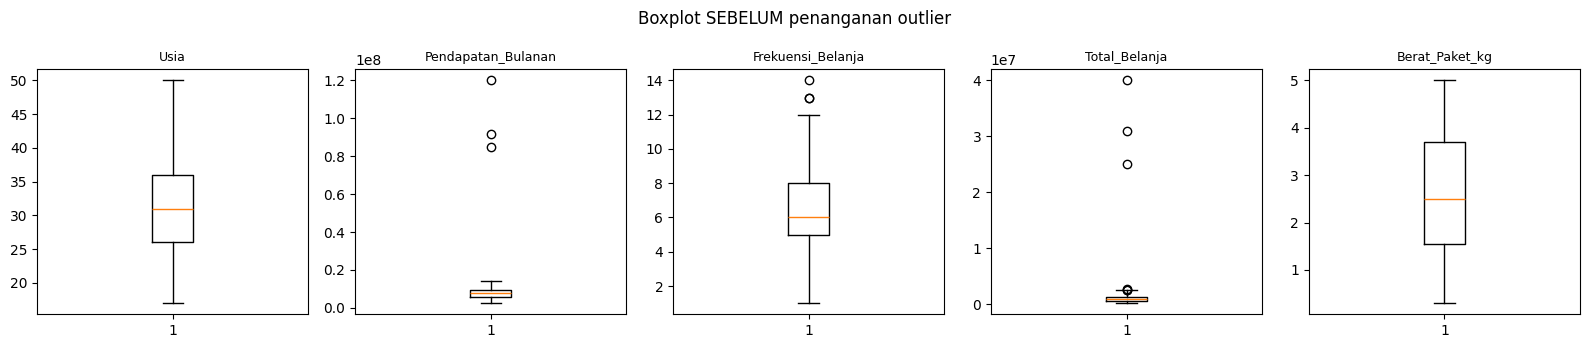

Pendapatan_Bulanan | batas: 825000 - 14225000 | outlier: [120000000.0, 92000000.0, 85000000.0]
Total_Belanja | batas: -448250 - 2487750 | outlier: [2784000.0, 2566000.0, 40000000.0, 2516000.0, 25000000.0, 31000000.0]


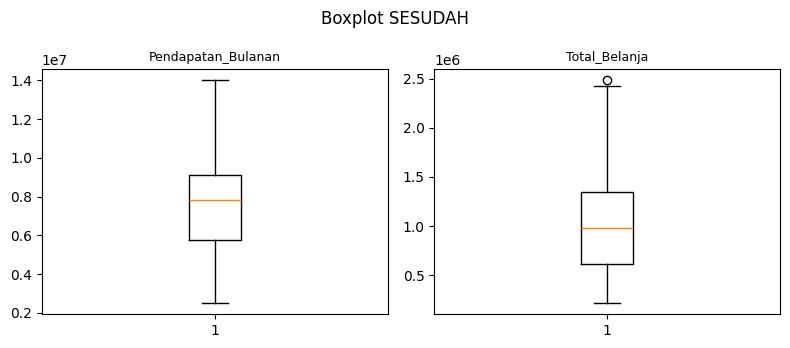

In [16]:
import os
os.makedirs('figs', exist_ok=True)

num_cols = ['Usia','Pendapatan_Bulanan','Frekuensi_Belanja','Total_Belanja','Berat_Paket_kg']
fig,ax = plt.subplots(1,5,figsize=(16,3.5))
for a,c in zip(ax,num_cols): a.boxplot(df[c].dropna()); a.set_title(c, fontsize=9)
plt.suptitle('Boxplot SEBELUM penanganan outlier'); plt.tight_layout(); plt.savefig('figs/boxplot_sebelum.png',dpi=130); plt.show()
R['outlier']={}
for c in ['Pendapatan_Bulanan','Total_Belanja']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1; lo,hi=q1-1.5*iqr,q3+1.5*iqr
    m=(df[c]<lo)|(df[c]>hi)
    R['outlier'][c]={'batas_bawah':round(lo),'batas_atas':round(hi),'nilai':df.loc[m,c].tolist()}
    print(c,'| batas:',round(lo),'-',round(hi),'| outlier:',df.loc[m,c].tolist())
    df.loc[m,c]=np.nan
fig,ax = plt.subplots(1,2,figsize=(8,3.5))
for a,c in zip(ax,['Pendapatan_Bulanan','Total_Belanja']): a.boxplot(df[c].dropna()); a.set_title(c, fontsize=9)
plt.suptitle('Boxplot SESUDAH'); plt.tight_layout(); plt.savefig('figs/boxplot_sesudah.png',dpi=130); plt.show()

### 2.7 Missing value
**Input:** `df` (missing asli + yang berasal dari nilai mustahil/outlier). **Proses:** (a) deteksi jumlah & persentase; (b) **statistik deskriptif**: cek skewness; jika |skew| > 0,5 gunakan **median**, jika tidak **mean** untuk numerik; **modus** untuk kategorik; (c) imputasi. **Output:** tidak ada missing value.

,jumlah,persen
Nama,4,3.3
Jenis_Kelamin,6,5.0
Usia,11,9.2
Kota,7,5.8
Pendapatan_Bulanan,12,10.0
Frekuensi_Belanja,10,8.3
Total_Belanja,16,13.3
Metode_Pembayaran,8,6.7
Berat_Paket_kg,5,4.2
Tingkat_Kepuasan,9,7.5


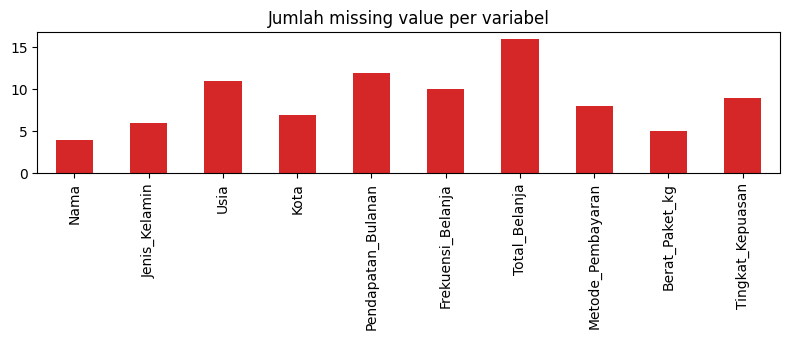

In [17]:
miss = pd.DataFrame({'jumlah':df.isna().sum(),'persen':(df.isna().mean()*100).round(1)})
display(miss[miss.jumlah>0])
R['missing_sebelum_imputasi'] = miss[miss.jumlah>0].reset_index().rename(columns={'index':'Variabel'}).to_dict('records')
fig,ax=plt.subplots(figsize=(8,3.5)); miss[miss.jumlah>0].jumlah.plot.bar(ax=ax,color='tab:red'); ax.set_title('Jumlah missing value per variabel')
plt.tight_layout(); plt.savefig('figs/missing.png',dpi=130); plt.show()

In [18]:
stat = pd.DataFrame({'mean':df[num_cols].mean(),'median':df[num_cols].median(),'std':df[num_cols].std(),'skew':df[num_cols].skew()}).round(2)
stat['metode'] = np.where(stat['skew'].abs()>0.5,'median','mean'); display(stat)
R['stat_deskriptif'] = stat.reset_index().rename(columns={'index':'Variabel'}).to_dict('records')
for c in num_cols:
    df[c] = df[c].fillna(df[c].median() if stat.loc[c,'metode']=='median' else df[c].mean())
# pembulatan variabel yang bersifat bilangan bulat
df['Usia']=df['Usia'].round().astype(int); df['Frekuensi_Belanja']=df['Frekuensi_Belanja'].round().astype(int)
cat_cols=['Jenis_Kelamin','Kota','Metode_Pembayaran','Tingkat_Kepuasan']
R['modus']={}
for c in cat_cols:
    R['modus'][c]=df[c].mode()[0]; df[c]=df[c].fillna(df[c].mode()[0])
df['Nama']=df['Nama'].fillna('Tidak Diketahui')
print('Sisa missing:', int(df.isna().sum().sum())); R['modus']

,mean,median,std,skew,metode
Usia,30.82,31.0,7.73,0.12,mean
Pendapatan_Bulanan,7645370.37,7850000.0,2360872.02,0.10,mean
Frekuensi_Belanja,6.56,6.0,2.69,0.42,mean
Total_Belanja,1061230.77,979000.0,552949.55,0.72,median
Berat_Paket_kg,2.60,2.5,1.34,0.05,mean


Sisa missing: 0


{'Jenis_Kelamin': 'Laki-Laki',
 'Kota': 'Surabaya',
 'Metode_Pembayaran': 'E-Wallet',
 'Tingkat_Kepuasan': 'Sedang'}

In [19]:
R['shape_bersih']=list(df.shape); df.to_csv('Dataset_Bersih.csv',index=False); display(df.describe().T.round(2)); df.head()

,count,mean,std,min,25%,50%,75%,max
Usia,120.0,30.83,7.37,17.0,26.0,31.00,35.25,50.0
Pendapatan_Bulanan,120.0,7645370.37,2238673.99,2500000.0,6000000.0,7645370.37,8925000.00,14000000.0
Frekuensi_Belanja,120.0,6.60,2.58,1.0,5.0,7.00,8.00,14.0
Total_Belanja,120.0,1050266.67,515200.42,216000.0,673250.0,979000.00,1291500.00,2480000.0
Berat_Paket_kg,120.0,2.60,1.31,0.3,1.6,2.60,3.70,5.0


,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Pendapatan_Bulanan,Frekuensi_Belanja,Total_Belanja,Kategori_Produk,Metode_Pembayaran,Berat_Paket_kg,Tingkat_Kepuasan,Langganan_Premium
0,CUST001,Citra Utami,Perempuan,40,Surabaya,1.200000e+07,9,2237000.0,Rumah Tangga,E-Wallet,4.3,Tinggi,Tidak
1,CUST002,Reza Kurniawan,Laki-Laki,23,Malang,6.700000e+06,12,1748000.0,Kecantikan,Transfer Bank,0.9,Tinggi,Tidak
2,CUST003,Ilham Utami,Laki-Laki,17,Sidoarjo,1.040000e+07,5,1249000.0,Rumah Tangga,Transfer Bank,1.9,Sedang,Tidak
3,CUST004,Tidak Diketahui,Perempuan,41,Malang,7.645370e+06,6,979000.0,Rumah Tangga,Cod,4.1,Sedang,Tidak
4,CUST005,Rizky Hakim,Laki-Laki,27,Malang,8.600000e+06,6,531000.0,Kecantikan,E-Wallet,0.4,Tinggi,Tidak


## 3. Transforming
### 3.1 Normalisasi
**Input:** `Usia`, `Pendapatan_Bulanan`, `Frekuensi_Belanja`, `Total_Belanja`. **Proses:** decimal scaling, min–max, z-score, robust scaling. **Output:** kolom ternormalisasi.

In [20]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
cn=['Usia','Pendapatan_Bulanan','Frekuensi_Belanja','Total_Belanja']
dn=pd.DataFrame(index=df.index)
k=int(np.ceil(np.log10(df['Pendapatan_Bulanan'].max()+1)))
dn['Pendapatan_DecScale']=df['Pendapatan_Bulanan']/10**k
mm=pd.DataFrame(MinMaxScaler().fit_transform(df[cn]),columns=[c+'_MinMax' for c in cn])
zs=pd.DataFrame(StandardScaler().fit_transform(df[cn]),columns=[c+'_Z' for c in cn])
rb=pd.DataFrame(RobustScaler().fit_transform(df[cn]),columns=[c+'_Robust' for c in cn])
norm=pd.concat([dn,mm,zs,rb],axis=1); print('k decimal scaling =',k)
display(norm.describe().T[['mean','std','min','max']].round(3))
R['normalisasi']=norm.describe().T[['mean','std','min','max']].round(3).reset_index().rename(columns={'index':'Kolom'}).to_dict('records')
R['k']=k

k decimal scaling = 8


,mean,std,min,max
Pendapatan_DecScale,0.076,0.022,0.025,0.140
Usia_MinMax,0.419,0.223,0.000,1.000
Pendapatan_Bulanan_MinMax,0.447,0.195,0.000,1.000
Frekuensi_Belanja_MinMax,0.431,0.199,0.000,1.000
Total_Belanja_MinMax,0.368,0.228,0.000,1.000
Usia_Z,0.000,1.004,-1.886,2.613
Pendapatan_Bulanan_Z,0.000,1.004,-2.308,2.850
Frekuensi_Belanja_Z,0.000,1.004,-2.179,2.879
Total_Belanja_Z,-0.000,1.004,-1.626,2.787
Usia_Robust,-0.018,0.796,-1.514,2.054


### 3.2 Encoding
**Input:** variabel kategorik. **Proses:** *one-hot* untuk nominal (`Jenis_Kelamin`, `Kota`, `Kategori_Produk`, `Metode_Pembayaran`); *label encoding* terurut untuk ordinal `Tingkat_Kepuasan` (Rendah=0, Sedang=1, Tinggi=2) dan target `Langganan_Premium` (Tidak=0, Ya=1). **Output:** semua variabel bertipe numerik.

In [21]:
nominal=['Jenis_Kelamin','Kota','Kategori_Produk','Metode_Pembayaran']
enc=pd.get_dummies(df,columns=nominal,dtype=int)
enc['Tingkat_Kepuasan']=enc['Tingkat_Kepuasan'].map({'Rendah':0,'Sedang':1,'Tinggi':2})
enc['Langganan_Premium']=enc['Langganan_Premium'].map({'Tidak':0,'Ya':1})
R['shape_encoding']=list(enc.shape); print(enc.shape); enc.head()

(120, 25)


,ID_Pelanggan,Nama,Usia,Pendapatan_Bulanan,Frekuensi_Belanja,Total_Belanja,Berat_Paket_kg,Tingkat_Kepuasan,Langganan_Premium,Jenis_Kelamin_Laki-Laki,Jenis_Kelamin_Perempuan,Kota_Gresik,Kota_Malang,Kota_Mojokerto,Kota_Sidoarjo,Kota_Surabaya,Kategori_Produk_Elektronik,Kategori_Produk_Fashion,Kategori_Produk_Kecantikan,Kategori_Produk_Makanan,Kategori_Produk_Rumah Tangga,Metode_Pembayaran_Cod,Metode_Pembayaran_E-Wallet,Metode_Pembayaran_Kartu Kredit,Metode_Pembayaran_Transfer Bank
0,CUST001,Citra Utami,40,1.200000e+07,9,2237000.0,4.3,2,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0
1,CUST002,Reza Kurniawan,23,6.700000e+06,12,1748000.0,0.9,2,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1
2,CUST003,Ilham Utami,17,1.040000e+07,5,1249000.0,1.9,1,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1
3,CUST004,Tidak Diketahui,41,7.645370e+06,6,979000.0,4.1,1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0
4,CUST005,Rizky Hakim,27,8.600000e+06,6,531000.0,0.4,2,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0


### 3.3 Diskretisasi (binning)
**Input:** `Usia`, `Total_Belanja`. **Proses:** *equal-width* pada `Usia` (4 bin) dan *equal-frequency* pada `Total_Belanja` (4 kuartil). **Output:** variabel kategorik baru.

In [22]:
df['Usia_Bin']=pd.cut(df['Usia'],bins=4)
df['Belanja_Kuartil']=pd.qcut(df['Total_Belanja'],q=4,labels=['Q1 (rendah)','Q2','Q3','Q4 (tinggi)'])
R['bin_usia']=df['Usia_Bin'].astype(str).value_counts().sort_index().to_dict()
R['bin_belanja']=df['Belanja_Kuartil'].value_counts().sort_index().to_dict()
print(R['bin_usia']); print(R['bin_belanja'])

{'(16.967, 25.25]': 27, '(25.25, 33.5]': 53, '(33.5, 41.75]': 31, '(41.75, 50.0]': 9}
{'Q1 (rendah)': 30, 'Q2': 38, 'Q3': 22, 'Q4 (tinggi)': 30}


## 4. Integrating Data
**Input:** `df` bersih. **Proses:** (a) *appending*: pisahkan 2 bagian lalu gabungkan kembali dengan `concat`; (b) *enriching aggregated measures*: hitung rata-rata belanja per kota lalu *join* ke tabel utama, serta rasio belanja terhadap pendapatan. **Output:** tabel dengan fitur tambahan.

In [23]:
a,b=df.iloc[:60],df.iloc[60:]; app=pd.concat([a,b],ignore_index=True)
print('Append sama dengan asli:',app.shape==df.shape)
agg=df.groupby('Kota').agg(Rata2_Belanja_Kota=('Total_Belanja','mean'),Jml_Pelanggan_Kota=('ID_Pelanggan','count')).round(0).reset_index()
df=df.merge(agg,on='Kota',how='left')
df['Rasio_Belanja_Pendapatan']=(df['Total_Belanja']/df['Pendapatan_Bulanan']).round(4)
R['agg_kota']=agg.to_dict('records'); display(agg); df[['Kota','Total_Belanja','Rata2_Belanja_Kota','Rasio_Belanja_Pendapatan']].head()

Append sama dengan asli: True


,Kota,Rata2_Belanja_Kota,Jml_Pelanggan_Kota
0,Gresik,1013389.0,18
1,Malang,997053.0,19
2,Mojokerto,1044222.0,9
3,Sidoarjo,942556.0,18
4,Surabaya,1115768.0,56


,Kota,Total_Belanja,Rata2_Belanja_Kota,Rasio_Belanja_Pendapatan
0,Surabaya,2237000.0,1115768.0,0.1864
1,Malang,1748000.0,997053.0,0.2609
2,Sidoarjo,1249000.0,942556.0,0.1201
3,Malang,979000.0,997053.0,0.1281
4,Malang,531000.0,997053.0,0.0617


## 5. Reduksi Dimensi
### 5.1 Feature Selection (target: `Langganan_Premium`)
**Input:** `enc` (numerik). **Proses:** *filter* (korelasi & F-test), *wrapper* (RFE), *embedded* (Logistic Regression L1/LASSO). **Output:** subset fitur penting.

In [24]:
from sklearn.feature_selection import f_classif, RFE
from sklearn.linear_model import LogisticRegression
X=enc.drop(columns=['ID_Pelanggan','Nama','Langganan_Premium']); y=enc['Langganan_Premium']
Xs=pd.DataFrame(StandardScaler().fit_transform(X),columns=X.columns)
filt=pd.DataFrame({'korelasi':X.corrwith(y).round(3),'F':f_classif(Xs,y)[0].round(2),'p':f_classif(Xs,y)[1].round(4)}).sort_values('F',ascending=False)
display(filt.head(8)); R['filter']=filt.head(6).reset_index().rename(columns={'index':'Fitur'}).to_dict('records')
rfe=RFE(LogisticRegression(max_iter=1000),n_features_to_select=5).fit(Xs,y); R['wrapper']=X.columns[rfe.support_].tolist(); print('RFE:',R['wrapper'])
lasso=LogisticRegression(penalty='l1',solver='liblinear',C=0.3).fit(Xs,y)
coef=pd.Series(lasso.coef_[0],index=X.columns); R['embedded']=coef[coef!=0].abs().sort_values(ascending=False).round(3).head(6).to_dict(); print('LASSO:',R['embedded'])

,korelasi,F,p
Frekuensi_Belanja,0.390,21.22,0.0000
Tingkat_Kepuasan,0.317,13.21,0.0004
Total_Belanja,0.263,8.77,0.0037
Pendapatan_Bulanan,0.178,3.85,0.0522
Kategori_Produk_Elektronik,0.146,2.56,0.1119
Kota_Mojokerto,0.119,1.70,0.1953
Metode_Pembayaran_Kartu Kredit,0.110,1.44,0.2323
Usia,-0.109,1.42,0.2358


RFE: ['Pendapatan_Bulanan', 'Frekuensi_Belanja', 'Tingkat_Kepuasan', 'Kota_Malang', 'Metode_Pembayaran_Transfer Bank']
LASSO: {'Frekuensi_Belanja': 0.664, 'Tingkat_Kepuasan': 0.22, 'Pendapatan_Bulanan': 0.148, 'Kota_Malang': 0.144, 'Kategori_Produk_Elektronik': 0.096, 'Kota_Mojokerto': 0.096}


### 5.2 Feature Extraction — PCA
**Input:** variabel numerik asli. **Proses:** z-score lalu PCA; lihat *explained variance*. **Output:** jumlah komponen yang mewakili ≥ 80% varians.

,PC,Varians (%),Kumulatif (%)
0,PC1,36.3,36.3
1,PC2,19.5,55.9
2,PC3,17.0,72.8
3,PC4,14.6,87.5
4,PC5,8.1,95.6
5,PC6,4.4,100.0


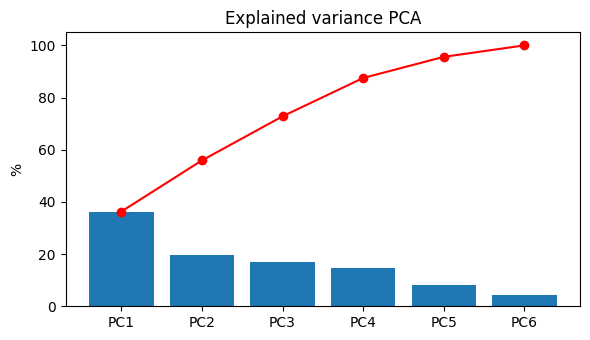

Komponen utk >=80%: 4


In [25]:
from sklearn.decomposition import PCA
cols=['Usia','Pendapatan_Bulanan','Frekuensi_Belanja','Total_Belanja','Berat_Paket_kg','Tingkat_Kepuasan']
Z=StandardScaler().fit_transform(enc[cols]); p=PCA().fit(Z)
ev=pd.DataFrame({'PC':[f'PC{i+1}' for i in range(len(cols))],'Varians (%)':(p.explained_variance_ratio_*100).round(1),'Kumulatif (%)':(p.explained_variance_ratio_.cumsum()*100).round(1)}); display(ev)
R['pca']=ev.to_dict('records'); R['pca_n80']=int((p.explained_variance_ratio_.cumsum()<0.8).sum()+1)
R['pca_loading']=pd.DataFrame(p.components_[:2].T,index=cols,columns=['PC1','PC2']).round(2).reset_index().rename(columns={'index':'Variabel'}).to_dict('records')
plt.figure(figsize=(6,3.5)); plt.bar(ev.PC,ev['Varians (%)']); plt.plot(ev.PC,ev['Kumulatif (%)'],'o-r'); plt.ylabel('%'); plt.title('Explained variance PCA')
plt.tight_layout(); plt.savefig('figs/pca.png',dpi=130); plt.show(); print('Komponen utk >=80%:',R['pca_n80'])

## 6. Simpan Hasil
**Output:** dataset bersih dan ringkasan hasil.

In [26]:
enc.to_csv('Dataset_Siap_Modeling.csv',index=False)
json.dump(R,open('hasil.json','w'),default=str,indent=1); print('Selesai. Baris x kolom akhir:',enc.shape)

Selesai. Baris x kolom akhir: (120, 25)
